# 02 - Resistance cost and private benefit: α, β_min, c

**Question.** How do the cost of resistance (α), the private protection of the resistant strain
(β_min) and the inhibitor's efficacy inside resistant cells (c) decide who wins after one dose?
These are the three strain traits in the paper's simplified selection criterion (Eq. 2), which also contains γ.

**Sweep.** 21 × 21 × 21 = 9,261 runs at the Fig. 2C dose (a0 = 2.15, i = 10); all other parameters
at their SI base values. Produced by `01_run_sweeps.ipynb`.

In [1]:
from pathlib import Path
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
TABLES = PROJECT_ROOT / "results" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None); pd.set_option("display.width", 160)

from dataclasses import replace
from src.model.ma2024_model import DEFAULT_PARAMS, BASE_A0, BASE_I
from src.analysis import sweep_engine as engine
from src.analysis.grid_runner import axis, BASE_VALUES, RANGES, LOG_AXES
from src.analysis.plotting import (heatmap_slices, pair_heatmaps, marginal_effects, outcome_map,
                                   outcome_counts, timecourses, select, label, SHORT, OKABE_ITO, OUTCOME_COLORS)

PARAMS = ['alpha', 'beta_min', 'c']
df = pd.read_csv(TABLES / "grid_alpha_betamin_c.csv")
with np.errstate(divide="ignore"):
    df["log10_f_R"] = np.log10(df.f_R_final)
    df["log10_ns_min"] = np.log10(df.ns_min.clip(lower=1e-30))
    df["log10_nr_min"] = np.log10(df.nr_min.clip(lower=1e-30))
settled = df[~df.outcome.isin(["community collapsed", "not converged"])]
print(f"{len(df):,} runs; {len(settled):,} settled; fixed dose: " +
      ", ".join(f"{k} = {BASE_VALUES[k]:g}" for k in ("a0", "i") if k not in PARAMS))
pd.DataFrame([{"parameter": k, "base": BASE_VALUES[k], "min": df[k].min(), "max": df[k].max(),
               "values": df[k].nunique(), "spacing": "log" if k in LOG_AXES else "linear"} for k in PARAMS])

9,261 runs; 9,261 settled; fixed dose: a0 = 2.15, i = 10


,parameter,base,min,max,values,spacing
0,alpha,0.95,0.75,1.0,21,linear
1,beta_min,0.90,0.00,1.0,21,linear
2,c,0.70,0.00,1.0,21,linear


## Overview of the endpoints

Minimum, median and maximum over the settled runs, and the value at the base point.

In [2]:
cols = ["f_R_final", "diversity_final", "total_final", "peak_loss_S", "peak_loss_total",
        "t_regain_S", "t_90_final_S", "t_steady_state"]
overview = settled[cols].describe().T[["min", "50%", "max"]].rename(columns={"50%": "median"})
base = select(df, {k: BASE_VALUES[k] for k in PARAMS})
overview["base point"] = base[cols].iloc[0].values
overview.index = [label(c) for c in cols]
print(f"S viable at the end: {df.sensitive_survives.mean():.1%} of runs | R gained share (f_R rose): "
      f"{(df.delta_log_ratio > 0).mean():.1%} | needed a horizon beyond 150: {(df.t_end > 150).mean():.1%}")
overview.round(3)

S viable at the end: 81.6% of runs | R gained share (f_R rose): 54.0% | needed a horizon beyond 150: 0.0%


,min,median,max,base point
Final resistant fraction f_R,0.001,0.529,0.845,0.433
Final Shannon diversity H,0.007,0.620,0.693,0.684
Final total density,3.043,4.026,4.338,3.832
Peak S loss,0.148,0.299,0.708,0.394
Peak total loss,0.000,0.218,0.844,0.410
S recovery time (back to start),2.500,5.500,25.500,8.500
Time for S to reach 90% of final,4.000,10.000,36.500,13.500
Time to steady state,6.000,11.500,39.500,15.500


## Outcome classes

**Plain model:** the paper's equations as they are. **With floor:** a population that falls below
one cell (10⁻⁹ of the carrying capacity) is removed for good. The two only differ when a run passes
through a very deep crash.

In [3]:
both = pd.concat([outcome_counts(df, "outcome").add_prefix("plain model: "),
                  outcome_counts(df, "outcome_floor").add_prefix("with floor: ")], axis=1).fillna(0)
both

,plain model: runs,plain model: % of grid,with floor: runs,with floor: % of grid
"S viable, R persists",7560,81.63,7560,81.63
"S not viable, R persists",1701,18.37,1701,18.37


## Final resistant fraction

Each panel is one value of β_min (0 = strongest private protection, 1 = none). x-axis: c, y-axis: α.
The red cross marks the base point (in the panel that contains it).

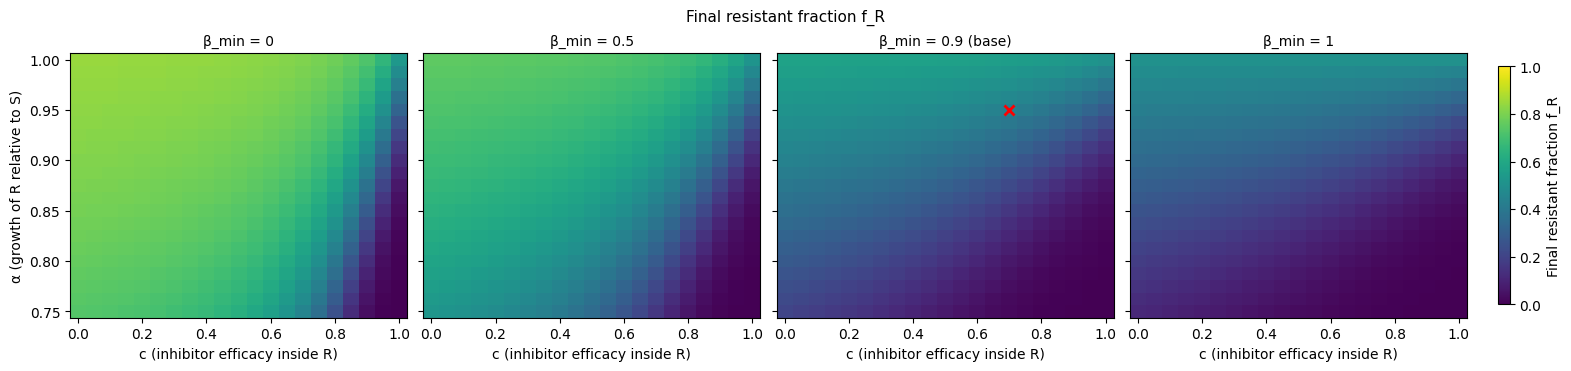

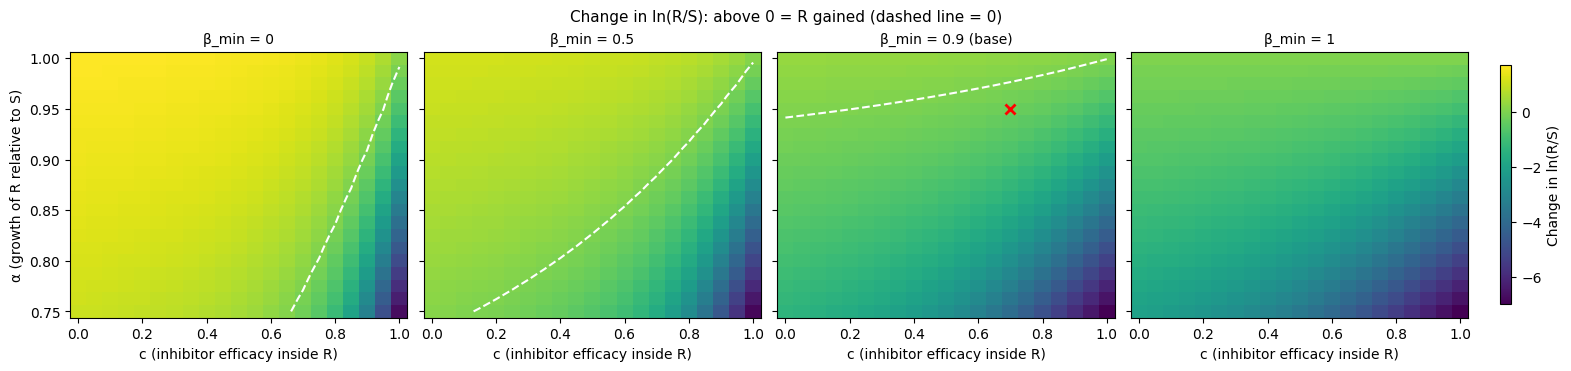

In [4]:
SL = [0.0, 0.5, 0.9, 1.0]
heatmap_slices(df, "c", "alpha", "f_R_final", "beta_min", SL, vmin=0, vmax=1); plt.show()
heatmap_slices(df, "c", "alpha", "delta_log_ratio", "beta_min", SL, diverging=True,
               title="Change in ln(R/S): above 0 = R gained (dashed line = 0)"); plt.show()

### How small does R get?

A linear scale hides how far R is pushed down. The table counts runs below each candidate extinction
threshold on f_R (10⁻⁹ = cleared and 10⁻⁶ = suppressed are the thresholds used throughout; "eradicated" is reserved for the one-cell density floor).

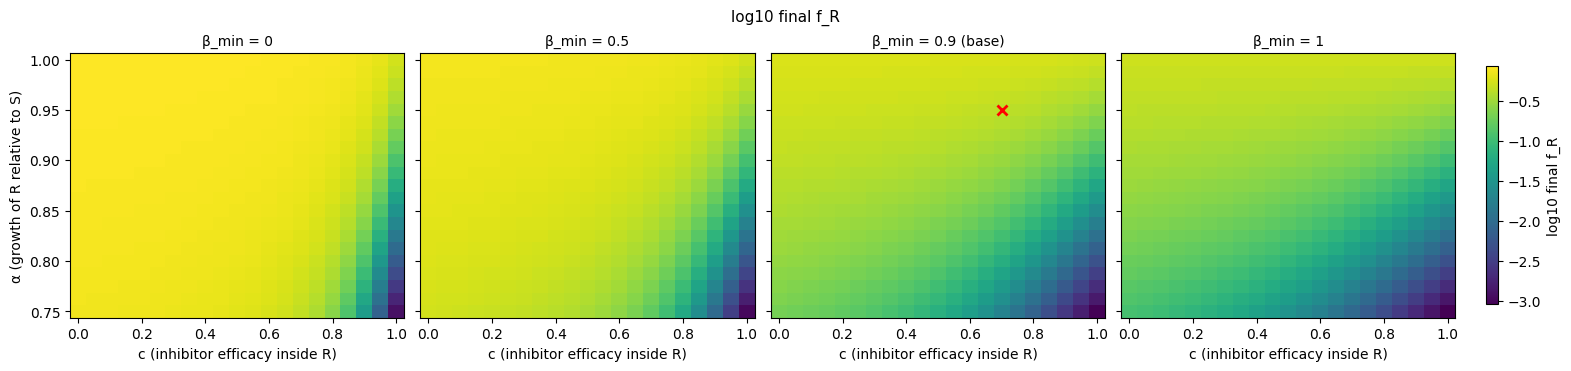

Lowest final f_R: 9.12e-04 at alpha = 0.75, beta_min = 1, c = 1; lowest R density reached anywhere: 1.24e-03 (extinction floor 4.4e-09)


,threshold on f_R,runs below,% of grid
0,0.1,988,10.67
1,0.01,245,2.65
2,0.001,7,0.08
3,0.0001,0,0.00
4,1e-06,0,0.00
5,1e-09,0,0.00


In [5]:
heatmap_slices(df, "c", "alpha", "log10_f_R", "beta_min", SL); plt.show()
thr = pd.DataFrame([{"threshold on f_R": f"{t:g}", "runs below": int((df.f_R_final < t).sum()),
                     "% of grid": round((df.f_R_final < t).mean() * 100, 2)} for t in (1e-1, 1e-2, 1e-3, 1e-4, 1e-6, 1e-9)])
low = df.loc[df.f_R_final.idxmin()]
print(f"Lowest final f_R: {low.f_R_final:.2e} at alpha = {low.alpha:g}, beta_min = {low.beta_min:g}, c = {low.c:g}; "
      f"lowest R density reached anywhere: {df.nr_min.min():.2e} (extinction floor {engine.EXTINCTION_FLOOR:.1e})")
thr

## Does S stay viable?

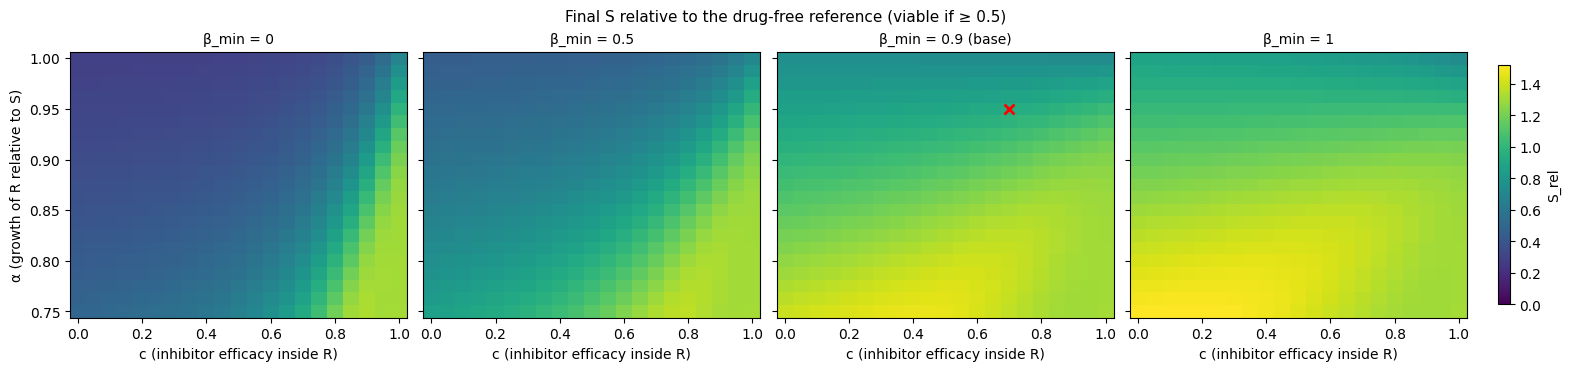

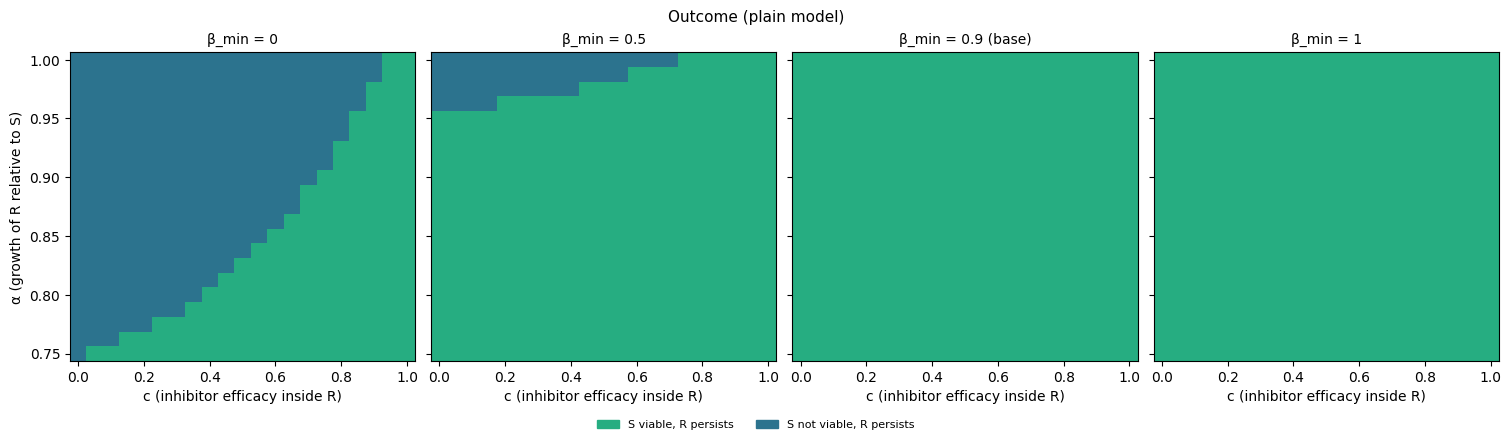

In [6]:
df["S_rel"] = df.ns_final / engine.no_drug_reference()
heatmap_slices(df, "c", "alpha", "S_rel", "beta_min", SL, vmin=0, title="Final S relative to the drug-free reference (viable if ≥ 0.5)"); plt.show()
outcome_map(df, "c", "alpha", "beta_min", SL, column="outcome"); plt.show()

## Depth of the crash and recovery time

Peak loss is the largest drop below the starting density. Recovery time is the time for S to get back to its starting density.

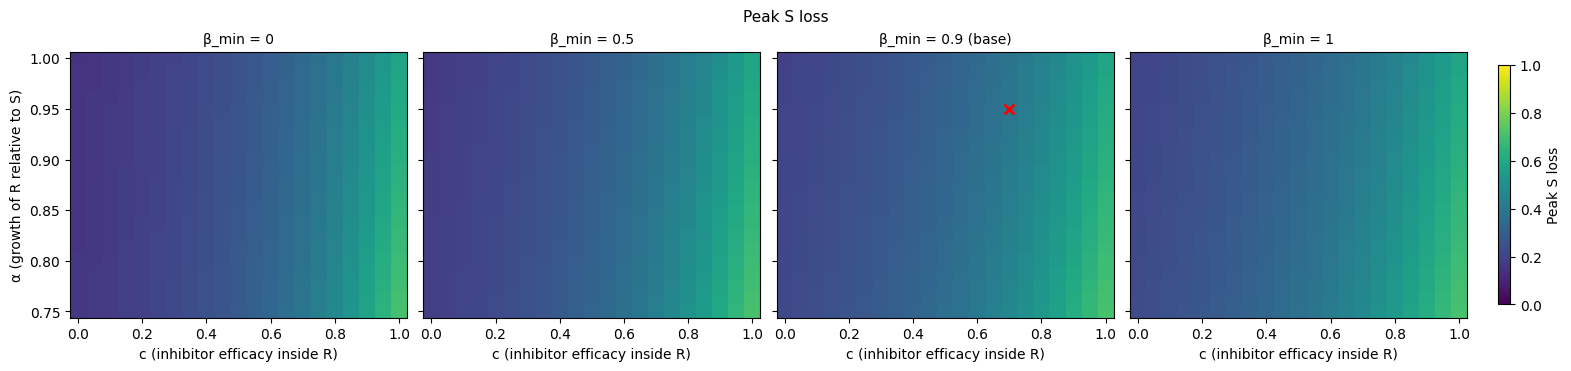

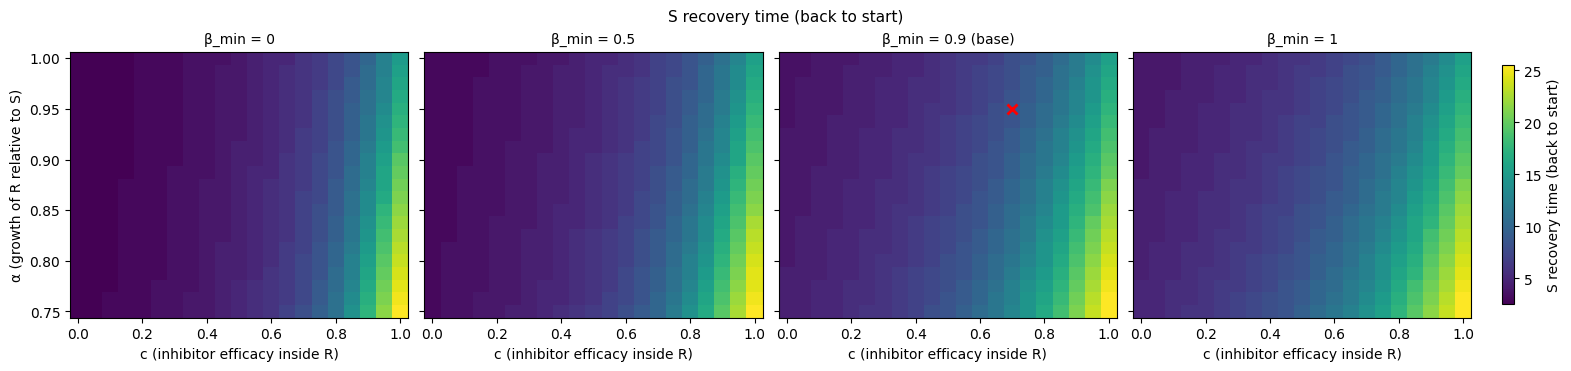

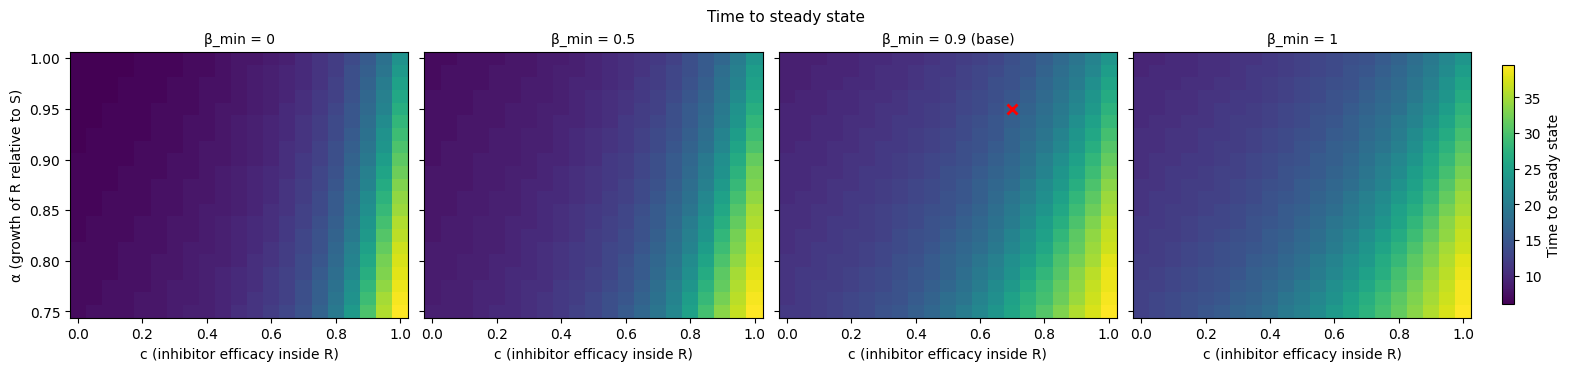

In [7]:
heatmap_slices(df, "c", "alpha", "peak_loss_S", "beta_min", SL, vmin=0, vmax=1); plt.show()
heatmap_slices(df, "c", "alpha", "t_regain_S", "beta_min", SL); plt.show()
heatmap_slices(df, "c", "alpha", "t_steady_state", "beta_min", SL); plt.show()

## Diversity

With two strains, Shannon diversity is a function of f_R alone (highest at 50/50), so it must be read together with f_R.

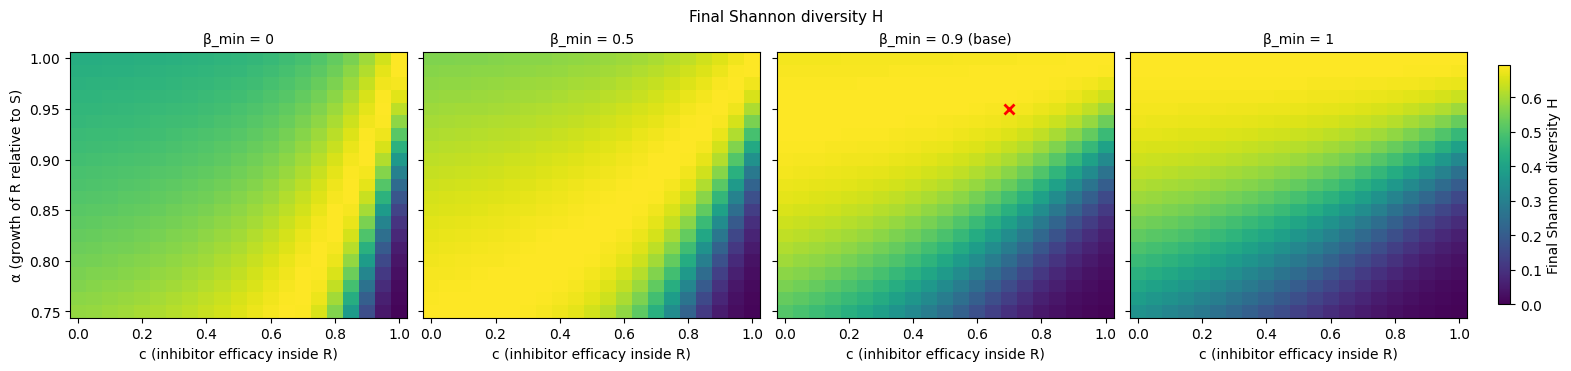

In [8]:
heatmap_slices(df, "c", "alpha", "diversity_final", "beta_min", SL, vmin=0, vmax=np.log(2)); plt.show()

## Effect of each parameter

Blue: median over the rest of the grid, with the 10-90% band. Dashed: the other two parameters at base (the decoupled, one-at-a-time effect).

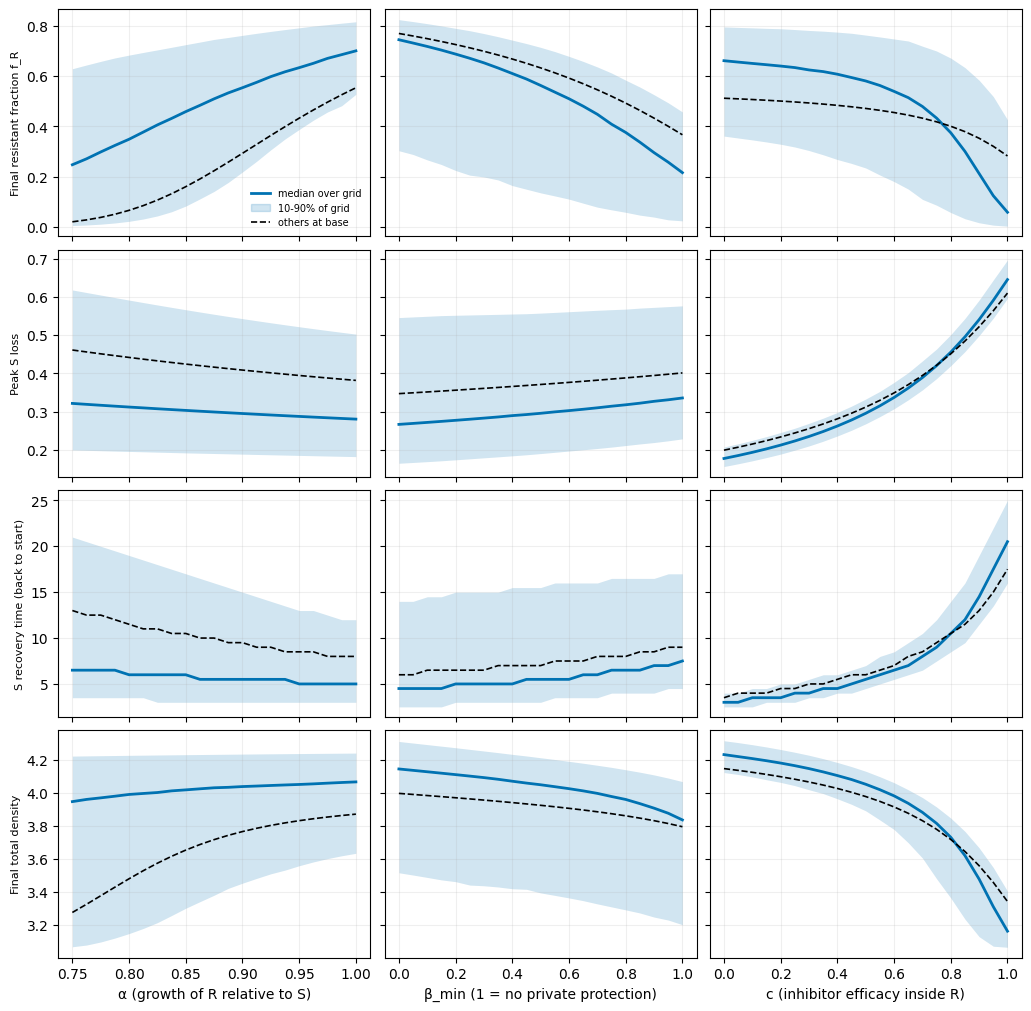

In [9]:
marginal_effects(df, PARAMS, ["f_R_final", "peak_loss_S", "t_regain_S", "total_final"]); plt.show()

## Example time courses

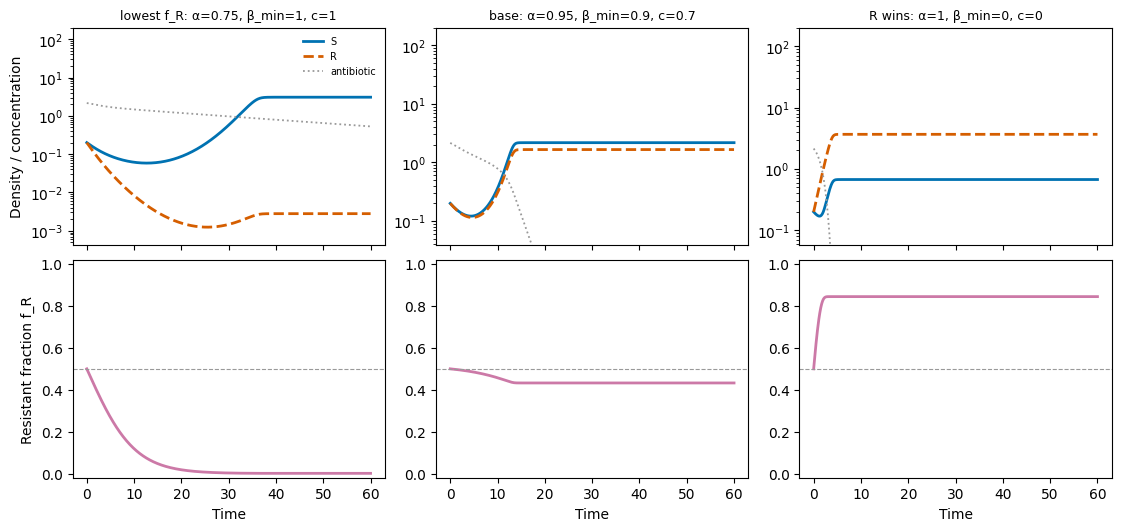

In [10]:
timecourses([("lowest f_R: α=0.75, β_min=1, c=1", {"alpha": 0.75, "beta_min": 1.0, "c": 1.0}),
             ("base: α=0.95, β_min=0.9, c=0.7", {}),
             ("R wins: α=1, β_min=0, c=0", {"alpha": 1.0, "beta_min": 0.0, "c": 0.0})], t_end=60); plt.show()

## Rank sensitivity over the whole grid

In [11]:
ends = ["f_R_final", "diversity_final", "total_final", "peak_loss_S", "t_regain_S", "t_steady_state"]
rho = pd.DataFrame({label(e): [settled[[p, e]].corr(method="spearman").iloc[0, 1] for p in PARAMS] for e in ends},
                   index=[SHORT[p] for p in PARAMS])
print("Spearman rank correlation between each parameter and each endpoint, over the whole grid:")
rho.round(2)

Spearman rank correlation between each parameter and each endpoint, over the whole grid:


,Final resistant fraction f_R,Final Shannon diversity H,Final total density,Peak S loss,S recovery time (back to start),Time to steady state
α,0.51,0.18,0.14,-0.10,-0.15,-0.25
β_min,-0.59,0.10,-0.33,0.17,0.26,0.36
c,-0.52,-0.20,-0.91,0.97,0.94,0.87


## Takeaways

- **Who wins.** R gains ground in 54% of the grid. A larger cost of resistance (lower α), weaker private
  protection (higher β_min) and a more effective inhibitor (higher c) all push towards S (rank
  correlations with final f_R: +0.51, −0.59, −0.52). With no private protection (β_min = 1) R never
  gains; with the strongest protection (β_min = 0) it gains in 83% of the (α, c) plane.
- **R is never eliminated at this dose.** The lowest final f_R is 9 × 10⁻⁴ (α = 0.75, c = 1) and the
  lowest R density reached in any run is 1.2 × 10⁻³, about five orders of magnitude above one cell.
  The extinction floor therefore changes nothing here. 10.7% of runs end with f_R < 0.1, 2.7% with
  f_R < 0.01 (all with α ≤ 0.8125 and c ≥ 0.7) and 7 runs with f_R < 10⁻³.
- **S stays viable in 81.6% of runs.** It falls below the viability line only when R keeps strong
  private protection (β_min ≤ 0.55) and the inhibitor is not fully effective (c ≤ 0.9).
- **c sets the depth of the crash** (rank correlation with peak S loss: 0.97). Median peak S loss
  rises from 18% at c = 0 to 64% at c = 1. About five sixths of that rise (83%) comes from c
  reducing antibiotic degradation by living R, so the drug stays longer for everyone; the loss of
  private protection alone adds under a tenth, and the rest appears only when both act (the inhibitor's
  actions are separated in notebook 04). The settings that suppress R best are the ones
  with the deepest S crash (up to 71%) and the longest recovery (up to 25.5 time units).
- **Diversity carries no extra information here.** With two strains it is a function of f_R alone.
- **Caveats.** One dose (a0 = 2.15, i = 10). c acts on two mechanisms at once; notebook 04 separates
  them. The paper's selection criterion for these three parameters is checked in notebook 06.